# ▓▒░ PIXL :: STAGE 2 :: FINE TUNE WITH CLIP CAPTIONS ░▒▓

Fine-tunes the pixel model on pixel art, with captions read by the frozen CLIP text encoder (`openai/clip-vit-base-patch32`) instead of text embeddings learned from scratch. One run teaches three things:

1. **Colour and monochrome:** every monochrome sprite's label starts with "monochrome" (see Experiment), so "skeleton" and "monochrome skeleton" ask for different pictures.
2. **Objects:** phase 1 trains on single sprites, mostly with their main noun as the caption ("shield", "sword").
3. **Positions:** phase 2 trains on scenes ("a pine tree left of a wooden barrel on grass"), with some sprites kept so objects are not forgotten.

| | |
|---|---|
| **Start** | Stage 1's best weights (`checkpoints/pretrain-best.pt`) except the caption input, a new linear layer from CLIP's 512-wide token outputs |
| **Data** | Sprites (CC0 packs and game-icons.net icons), scenes built from the CC0 sprites; photos are only tested |
| **Length** | 8,000 steps of 16 samples: 5,000 for objects, 3,000 for positions; about 2.3 hours at ~1 s per step |

**Run the cells in order.** Every `EVAL_EVERY` steps, and at the end of each phase, the notebook measures the test losses, draws the preview, saves `checkpoints/<RUN>.pt` and logs a line. Interrupt any time (■ / Kernel ▸ Interrupt) and run the training cell again to continue. Set `QUICK = True` for a short trial run.

In [1]:
import itertools
import math
import os
import random
import re
import sys
import time
from dataclasses import asdict, dataclass, field
from pathlib import Path

# Run from the project root, so src/ and its palette and tokenizer files are found.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))
# Cap the GPU memory PyTorch keeps (macOS recommends 17.8 GB on a 24 GB Mac): cached memory is released
# above 0.6x (~10.7 GB) and allocations fail above 0.9x (~16 GB). PyTorch's defaults (1.4x and 1.7x) exceed
# physical memory, so the cache grows until the Mac swaps to a halt. Must be set before torch is imported.
os.environ.setdefault("PYTORCH_MPS_HIGH_WATERMARK_RATIO", "0.9")
os.environ.setdefault("PYTORCH_MPS_LOW_WATERMARK_RATIO", "0.6")

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import HTML, display
from matplotlib import pyplot as plt
from torch.nn import functional as F
from torch.utils.data import ConcatDataset, DataLoader

from misc import retro
from scripts.scenes.generate import FRAGMENT, article
from src.data import load
from src.model import ClipPixl, ClipText, Config, Pixl, encode_captions
from src.preprocess import REPO, TRANSPARENT
from src.tokenizer import Tokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

print(f"device {DEVICE} | torch {torch.__version__}")

device mps | torch 2.14.1


## Experiment

| Phase | Steps | Trains on | Sprite captions | Learns |
|---|---|---|---|---|
| 1. objects | 5,000 | sprites only | main noun 80%, full label 20% | what each object looks like |
| 2. positions | 3,000 | scenes 80%, sprites 20% | main noun 20%, full label 80% | where objects are, without forgetting them |

### Colour and monochrome

The 1-Bit Pack draws each tile in colour and in white, the Cursor Pixel Pack and Monochrome Pirates are drawn in one colour, and the game-icons.net icons are white silhouettes. Their labels start with "monochrome", and colour words copied from a tile's coloured version are removed: the white copy of "brown stone tile floor" is "monochrome stone tile floor". Without this, one caption asked for four different pictures. The 1-Bit Pack's copies of objects on a dark square were dropped; its ground tiles keep theirs, since scenes use them. Main nouns keep the word: "monochrome skeleton" becomes "monochrome skeleton", not "skeleton".

### Objects: main nouns

A sprite is shown with its main noun instead of its label with the phase's `coarse` chance: "white tower shield" becomes "shield", "rock troll" becomes "troll". Most full labels have one picture each, too few to learn a shape from; a main noun such as "shield" or "sword" has dozens. `coarse_caption` takes the last word before "with", "on", "in", "of", "at", "above" or "holding", skipping colour and size words; playing cards, digits and letters become "playing card", "digit" and "letter"; tile pieces (labels with "edge", "corner" and the like) keep their label. Test losses, previews and the comparison table always use full labels.

### Positions: scenes

Scenes are 32×32 pictures of one or two sprites on a background, with captions written from the placement, so they are always right. Phase 2 spends 80% of its samples on them; the 20% sprites keep phase 1's objects. Phase 2 starts from the model at the end of phase 1, which is also saved as `checkpoints/<RUN>-phase1.pt`, so phase 2 can be judged against it.

### Settings

| Field | Value | What it does |
|---|---|---|
| `init` | `"stage1"` | Starts from stage 1's weights; `"scratch"` starts from random ones |
| `phases` | `[(steps, mix), ...]` | Trains on each mix for that many steps, in order. A mix gives each source's chance per sample; keep all three keys |
| `coarse` | `[0.8, 0.2]` | Chance of the main noun for a sprite, per phase |
| `flip` | `True` | Mirrors sprites left-right half the time, except captions that name a direction or show text |
| `shift` | `2` | Moves each sprite by up to 2 pixels within its transparent border; its caption does not name a position |
| `dropout` | `0.1` | Randomly zeroes part of each block's output during training, so the model memorises less |
| `tags` | `None` | Optional caption prefix per source, e.g. `"pixel art of"` |

Every sprite is a 32×32 grid: `src/data.py` centres it and fills the rest with the transparent token, which is also why `shift` can move it.

**Learning rate:** each phase has its own warm-up and cosine decay, so phase 2 learns positions at the full learning rate instead of where phase 1 left off (warm restarts: [Loshchilov & Hutter 2017](https://arxiv.org/abs/1608.03983)).

**Checkpoints:** `checkpoints/<RUN>.pt` resumes the run; `<RUN>-best.pt` holds the weights with the lowest mean of the sprite and scene test losses, which comes from phase 2; `<RUN>-phase1.pt` holds the objects model. Change `RUN` before changing a setting, so a resume never mixes settings.

In [2]:
@dataclass(frozen=True)
class Experiment:
    """Settings of a stage 2 run; the tables above explain each.

    Attributes:
        init: "stage1" starts from stage 1's weights except the caption input; "scratch" from random weights.
        phases: (steps, mix) pairs trained in order; a mix gives each source's chance per sample.
        coarse: Chance that a sprite is shown with its main noun instead of its label; one per phase.
        flip: Whether sprites are mirrored left-right half the time.
        shift: Largest random move of a sprite in pixels, within its transparent border.
        dropout: Dropout inside the blocks during training.
        tags: Text put before every caption of a source, or None for plain captions.
        mix: Each source's chance per sample when phases is None.
    """

    init: str = "stage1"
    phases: list[tuple[int, dict[str, float]]] | None = None
    coarse: float | list[float] = 0.0
    flip: bool = False
    shift: int = 0
    dropout: float = 0.0
    tags: dict[str, str] | None = None
    mix: dict[str, float] = field(default_factory=lambda: {"sprites": 0.45, "scenes": 0.45, "photos": 0.10})


RUN = "clip-objects-then-scenes"  # checkpoint name; starts with "clip-" so the comparison table finds it
experiment = Experiment(
    init="stage1",
    phases=[
        (5000, {"sprites": 1.0, "scenes": 0.0, "photos": 0.0}),  # 1. objects
        (3000, {"sprites": 0.2, "scenes": 0.8, "photos": 0.0}),  # 2. positions
    ],
    coarse=[0.8, 0.2],
    flip=True,
    shift=2,
    dropout=0.1,
)
INIT, MIX, TAGS, PHASES = experiment.init, experiment.mix, experiment.tags, experiment.phases
COARSE, FLIP, SHIFT, DROPOUT = experiment.coarse, experiment.flip, experiment.shift, experiment.dropout

## Settings

In [3]:
QUICK = False  # True: a short run that checks every cell works

STEPS = sum(steps for steps, _ in PHASES) if PHASES else 6000
BATCH = 16

# LR schedule
PEAK_LR = 3e-4
MIN_LR = 3e-5

WARMUP = 200  # per phase

WEIGHT_DECAY = 0.1
CLIP = 1.0
CAPTION_DROP = 0.1

LOG_EVERY = 10
EVAL_EVERY = 500
TEST_BATCHES = 32  # per source
SEED = 0

# The preview: 4 test sprites, these train sprites, and 4 test scenes, drawn at these settings.
PREVIEW_TRAIN = ["skeleton", "monochrome skeleton", "sword", "wooden barrel"]
PREVIEW_TEMPERATURE = 0.7
PREVIEW_GUIDANCE = 3.0

STAGE1 = Path("checkpoints/pretrain-best.pt")
CHECKPOINT = Path(f"checkpoints/{RUN}.pt")
BEST = Path(f"checkpoints/{RUN}-best.pt")
RESUME = True

if QUICK:
    STEPS, WARMUP, LOG_EVERY, EVAL_EVERY, TEST_BATCHES = 60, 20, 5, 30, 2
    CHECKPOINT, BEST = Path(f"checkpoints/{RUN}-quick.pt"), Path(f"checkpoints/{RUN}-quick-best.pt")
CHECKPOINT.parent.mkdir(exist_ok=True)

## Data

Each source is loaded as captions and 32×32 token grids ([`src/data.py`](../src/data.py)); the first load of sprites and scenes encodes them once. The order of all samples is drawn once from `SEED`, phase by phase, so a resumed run continues exactly where it stopped. The cell prints how often each train row is seen; watch the sprites test loss for overfitting.

The preview shows 4 test sprites (never trained on), the `PREVIEW_TRAIN` sprites (trained on: can the model draw what it has seen?), and 4 test scenes: 2 with unseen sprites and 2 with object pairs never seen together in training.

sprites  train 10,151 | test 1,135 | each train row seen ~8.8 times
scenes   train 100,000 | test 2,000 | each train row seen ~0.4 times
photos   train 82,651 | test 1,639 | each train row seen ~0.0 times
phase 1: steps 0-5,000 | sprites 100%, scenes 0%, photos 0%
phase 2: steps 5,000-8,000 | sprites 20%, scenes 80%, photos 0%
coarse captions: 2,759 main nouns for 7,159 sprite labels, e.g. 'monochrome interlaced tentacles' -> 'monochrome tentacles', 'white fence panel' -> 'panel', 'monochrome magnet' -> 'monochrome magnet', 'centaur barding metal' -> 'metal'


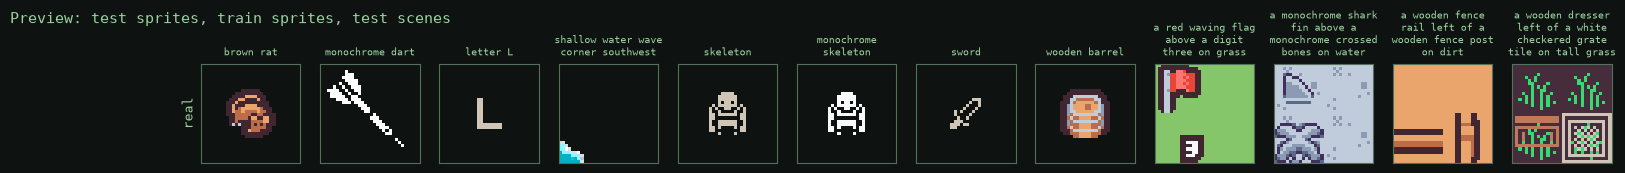

In [4]:
tokenizer = Tokenizer.load()
def load_source(name: str, split: str):
    """Loads one split with a "source" column, which picks each caption's TAGS prefix."""
    data = load(name, split)
    return data.add_column("source", [name] * len(data))


train_sets = {name: load_source(name, "train") for name in MIX}
test_sets = {name: load_source(name, "test") for name in MIX}
# Kind ("new sprites" or "new pair") and object labels of each test scene, in loader order.
scene_info = load_dataset(REPO, "scenes", split="test").select_columns(["kind", "objects"])

train_data = ConcatDataset(list(train_sets.values()))
# Each phase draws its steps from its own mix: a row gets its source's share, split evenly among the source's rows.
phases = PHASES or [(STEPS, MIX)]
lengths = [steps for steps, _ in phases]
if QUICK:  # keep the phases' proportions within the short run
    lengths = [max(1, round(STEPS * steps / sum(lengths))) for steps in lengths]
ends = list(itertools.accumulate(lengths))
spans = list(zip([0, *ends[:-1]], ends))
STEPS = ends[-1]


def phase_of(step: int) -> int:
    """Index of the phase a step belongs to."""
    return next((k for k, (_, end) in enumerate(spans) if step < end), len(spans) - 1)


generator = torch.Generator().manual_seed(SEED)
order = torch.cat([
    torch.multinomial(
        torch.cat([torch.full((len(data),), mix[name] / len(data)) for name, data in train_sets.items()]),
        (end - start) * BATCH, replacement=True, generator=generator,
    )
    for (_, mix), (start, end) in zip(phases, spans)
])
for name, data in train_sets.items():
    passes = sum(mix[name] * (end - start) * BATCH for (_, mix), (start, end) in zip(phases, spans)) / len(data)
    print(f"{name:8} train {len(data):>6,} | test {len(test_sets[name]):>5,} | each train row seen ~{passes:.1f} times")
if PHASES:
    for number, ((_, mix), (start, end)) in enumerate(zip(phases, spans), 1):
        print(f"phase {number}: steps {start:,}-{end:,} | " + ", ".join(f"{name} {share:.0%}" for name, share in mix.items()))

# A single COARSE value applies to every phase.
coarse_shares = COARSE if isinstance(COARSE, list) else [COARSE] * len(phases)
assert len(coarse_shares) == len(phases), "COARSE needs one value per phase"
# Colour and size words, which are never a label's main noun.
MODIFIERS = {"red", "green", "blue", "gray", "grey", "white", "black", "brown", "orange", "yellow", "purple", "pink",
             "dark", "light", "golden", "silver", "small", "large", "big", "tiny"}
# Kinds whose labels name the item after the noun, e.g. "two of diamonds playing card", "digit three".
KINDS = re.compile(r"\b(playing card|digit|letter)\b")
# Captions that a left-right mirror would make wrong: directions, and text, digits or symbols.
NO_FLIP = re.compile(r"\b(left|right|arrow|cursor|digit|letter|number|text|sign|percent|symbol)s?\b")


def coarse_caption(label: str) -> str | None:
    """The main noun of a sprite label, e.g. "white tower shield" -> "shield".

    "monochrome" stays: "monochrome skeleton" -> "monochrome skeleton". Returns None for tile
    pieces such as "dirt path corner on grass", which keep their label.
    """
    if FRAGMENT.search(label):
        return None
    style = "monochrome " if label.startswith("monochrome ") else ""
    label = label.removeprefix(style)
    if kind := KINDS.search(label):
        return style + kind[1]
    head = re.split(r"\b(?:with|on|in|of|at|above|holding)\b", label)[0].split()
    nouns = [word for word in head if word not in MODIFIERS and not word.isdigit()]
    return style + nouns[-1] if nouns else None


if any(coarse_shares):
    labels = sorted(set(train_sets["sprites"]["caption"]))
    nouns = {label: coarse_caption(label) for label in labels}
    examples = random.Random(SEED).sample([label for label in labels if nouns[label]], 4)
    print(f"coarse captions: {len(set(filter(None, nouns.values()))):,} main nouns for {len(labels):,} sprite labels, e.g. "
          + ", ".join(f"{label!r} -> {nouns[label]!r}" for label in examples))

pick = random.Random(SEED)
kinds = scene_info["kind"]
sprite_rows = pick.sample(range(len(test_sets["sprites"])), 4)
scene_rows = [i for kind in ("new sprites", "new pair") for i in pick.sample([j for j, k in enumerate(kinds) if k == kind], 2)]
train_captions = list(train_sets["sprites"]["caption"])
train_rows = [train_sets["sprites"][train_captions.index(label)] for label in PREVIEW_TRAIN]
preview_rows = [test_sets["sprites"][i] for i in sprite_rows] + train_rows + [test_sets["scenes"][i] for i in scene_rows]
PREVIEW = [row["caption"] for row in preview_rows]
PREVIEW_SOURCES = [row["source"] for row in preview_rows]
references = np.stack([row["tokens"].numpy() for row in preview_rows])
figure = retro.grid([("real", references)], PREVIEW, "Preview: test sprites, train sprites, test scenes")
plt.show()

## Model and optimiser

With `init="stage1"` the model starts from stage 1's best weights, except for the caption input: stage 1's learned text embedding is dropped, and a new linear layer reads CLIP's outputs. CLIP stays frozen and is not saved in the checkpoints. The optimiser starts fresh. The learning rate warms up and decays once per phase.

In [5]:
clip_text = ClipText(DEVICE)
torch.manual_seed(SEED)
if INIT == "stage1":
    stage1 = torch.load(STAGE1, map_location=DEVICE, weights_only=True)
    model = ClipPixl(Config(**(stage1["config"] | {"dropout": DROPOUT}))).to(DEVICE)
    missing, unexpected = model.load_state_dict(stage1["model"], strict=False)
    # Only the caption input differs from stage 1.
    assert sorted(missing) == ["text_in.bias", "text_in.weight"] and unexpected == ["text.weight"], (missing, unexpected)
    print(f"loaded {STAGE1}: stage 1 step {stage1['step']:,}, test loss {stage1['test_loss']:.3f}")
elif INIT == "scratch":
    model = ClipPixl(Config(dropout=DROPOUT)).to(DEVICE)
    print("random weights")
else:
    raise ValueError(f'INIT must be "stage1" or "scratch", not {INIT!r}')
# The caption prefixes this model trains with; caption_slot adds them.
model.tags = TAGS
# weights
matrices = [p for p in model.parameters() if p.dim() >= 2]
# biases and layer norms
others = [p for p in model.parameters() if p.dim() < 2]
optimizer = torch.optim.AdamW(
    [
        {"params": matrices, "weight_decay": WEIGHT_DECAY},
        {"params": others, "weight_decay": 0.0},
    ],
    lr=PEAK_LR,
    betas=(0.9, 0.95),
)

def learning_rate(step: int) -> float:
    """Within each phase: linear warm-up to PEAK_LR, then cosine decay to MIN_LR at the phase's end."""
    start, end = spans[phase_of(step)]
    local = step - start
    if local < WARMUP:
        return PEAK_LR * (local + 1) / WARMUP
    progress = min(1.0, (local - WARMUP) / max(1, end - start - WARMUP))
    return MIN_LR + 0.5 * (PEAK_LR - MIN_LR) * (1 + math.cos(math.pi * progress))

print(f"parameters {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] CLIPTextModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
logit_scale                                                    | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.l

loaded checkpoints/pretrain-best.pt: stage 1 step 15,495, test loss 1.353
parameters 14.6M


## Evaluation, samples and checkpoints

- **Test loss** per source, on the first `TEST_BATCHES` test batches of each, always the same images. `BEST` keeps the weights with the lowest mean of the sprite and scene losses; the photo loss shows how much of stage 1 is forgotten.
- **Preview** samples at `PREVIEW_TEMPERATURE` and `PREVIEW_GUIDANCE` with a fixed seed, so changes between evaluations come from training, not chance.
- **Checkpoints**: `CHECKPOINT` holds everything needed to resume; `BEST` and the phase files hold the weights and settings.

In [6]:
def caption_slot(net: Pixl, captions: list[str], sources: list[str], drop: float = 0.0) -> torch.Tensor:
    """The caption input net reads.

    Adds the TAGS prefix of each caption's source if net was trained with one, then
    gives CLIP outputs for a ClipPixl and learned-embedding ids otherwise.
    """
    tags = getattr(net, "tags", None)
    if tags:
        captions = [f"{tags[source]} {caption}" for caption, source in zip(captions, sources)]
    if isinstance(net, ClipPixl):
        return clip_text(captions, drop=drop)
    return encode_captions(captions, tokenizer, drop=drop).to(DEVICE)


def training_batch(batch: dict, step: int) -> tuple[list[str], torch.Tensor]:
    """The captions and pixels of one training step.

    With COARSE, a sprite gets its main noun with the current phase's chance. With FLIP, a sprite
    or photo is mirrored left-right half the time, unless its caption names a direction or shows
    text. With SHIFT, a sprite moves by up to SHIFT pixels within its transparent border. Scenes
    keep all three, since their captions name positions.

    Returns:
        (captions, (batch, 1024) pixel tokens on DEVICE).
    """
    phase = phase_of(step)
    captions, tokens = list(batch["caption"]), batch["tokens"].clone()
    for i, (caption, source) in enumerate(zip(batch["caption"], batch["source"])):
        if source == "scenes":
            continue
        if FLIP and not NO_FLIP.search(caption) and random.random() < 0.5:
            tokens[i] = tokens[i].flip(-1)
        if SHIFT and source == "sprites":
            rows, columns = torch.nonzero(tokens[i] != TRANSPARENT, as_tuple=True)
            if len(rows):
                last = tokens[i].shape[0] - 1
                down = random.randint(-min(SHIFT, int(rows.min())), min(SHIFT, last - int(rows.max())))
                across = random.randint(-min(SHIFT, int(columns.min())), min(SHIFT, last - int(columns.max())))
                # Only transparent border pixels wrap around, so the sprite itself stays whole.
                tokens[i] = tokens[i].roll((down, across), (0, 1))
        noun = coarse_caption(caption) if source == "sprites" else None
        if noun and random.random() < coarse_shares[phase]:
            captions[i] = noun
    return captions, tokens.flatten(1).to(DEVICE)


@torch.no_grad()
def pair_losses(net: Pixl, captions: list[str], tokens: torch.Tensor, sources: list[str]) -> torch.Tensor:
    """Mean loss per pixel of each (caption, image) pair: an (n,) tensor on the CPU."""
    ids = caption_slot(net, captions, sources)
    pixels = tokens.flatten(1).to(DEVICE)
    logits = net(ids, pixels)
    return F.cross_entropy(logits.transpose(1, 2), pixels, reduction="none").mean(1).cpu()


def test_losses(net: Pixl, data, batches: int | None) -> torch.Tensor:
    """Loss of each image in the first `batches` test batches, or in all of them for None."""
    loader = itertools.islice(DataLoader(data, batch_size=BATCH), batches)
    return torch.cat([pair_losses(net, batch["caption"], batch["tokens"], batch["source"]) for batch in loader])


@torch.no_grad()
def preview() -> torch.Tensor:
    """Samples one image per PREVIEW caption with a fixed seed: (n, 32, 32) uint8."""
    torch.manual_seed(SEED)  # training draws no torch random numbers, so this is safe
    captions = caption_slot(model, PREVIEW, PREVIEW_SOURCES)
    images = model.generate(captions, temperature=PREVIEW_TEMPERATURE, top_k=32, guidance=PREVIEW_GUIDANCE)
    return images.view(-1, 32, 32).to(torch.uint8).cpu()


def save_checkpoint() -> None:
    state = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "step": step,
        "train_log": train_log,
        "test_log": test_log,
        "snapshots": snapshots,
        "best": best,
    }
    torch.save(state, CHECKPOINT)


def weights(point: dict[str, float]) -> dict:
    """The model's weights and this run's settings, as BEST and the phase files hold them."""
    return {"model": model.state_dict(), "config": asdict(model.config), "step": step, "test_losses": point,
            "test_loss": (point["sprites"] + point["scenes"]) / 2, "init": INIT, "mix": MIX, "tags": TAGS,
            "phases": PHASES, "coarse": COARSE, "flip": FLIP, "shift": SHIFT}


def save_best(point: dict[str, float], loss: float) -> None:
    torch.save(weights(point), BEST)


def save_phase(number: int) -> None:
    """Saves the model at the end of a phase as <CHECKPOINT>-phase<number>.pt, e.g. the objects model."""
    torch.save(weights(test_log[-1]), CHECKPOINT.with_name(f"{CHECKPOINT.stem}-phase{number}.pt"))

## Live display

The same panel and dashboard as stage 1, with one test line per source. `best` is the lowest mean of the sprite and scene test losses so far.

In [7]:
def status(recent_steps: list[float]) -> str:
    """Builds the live panel from the latest logs."""
    seconds = sum(recent_steps) / max(1, len(recent_steps))
    losses = [p["loss"] for p in train_log]
    trend = "▼" if len(losses) > 1 and losses[-1] < losses[-2] else "▲" if len(losses) > 1 else " "
    tests = "   ".join(f"{name} {test_log[-1][name]:.3f}" for name in MIX) if test_log else "-----"
    best_test = f"{best:.3f}" if best < float("inf") else "-----"
    lines = [
        f"step {step:,}/{STEPS:,}   {step / STEPS:6.1%}   {RUN}   phase {phase_of(max(step - 1, 0)) + 1}/{len(spans)}",
        retro.bar(step / STEPS, 62),
        "",
        f"loss  {losses[-1] if losses else 0:6.3f} {trend}   best {best_test}",
        f"test  {tests}",
        f"lr    {learning_rate(max(step - 1, 0)):.2e}   speed {BATCH * 1056 / max(seconds, 1e-9):,.0f} tok/s",
        f"time  {retro.clock(time.time() - started)}   left {retro.clock((STEPS - step) * seconds)}",
        "",
        f"trend {retro.sparkline(losses, 56)}",
    ]
    return retro.panel("stage 2: fine-tune with CLIP", lines)


def evaluate() -> None:
    """Tests, samples, saves, logs a line and redraws the dashboard."""
    global best
    model.eval()
    point = {"step": step} | {name: test_losses(model, test_sets[name], TEST_BATCHES).mean().item() for name in MIX}
    test_log.append(point)
    images = preview()
    snapshots.append((step, images))
    loss = (point["sprites"] + point["scenes"]) / 2
    improved = loss < best
    if improved:
        best = loss
        save_best(point, loss)
    save_checkpoint()
    model.train()
    fields = {
        "time": retro.clock(time.time() - started),
        "step": f"{step:,}",
        "loss": f"{train_log[-1]['loss']:.3f}" if train_log else "-",
        **{name: f"{point[name]:.3f}" for name in MIX},
        "lr": f"{learning_rate(step - 1):.1e}",
    }
    print(retro.log_line(fields, highlight=improved))
    figure = retro.dashboard(train_log, test_log, images.numpy(), references, PREVIEW, f"Stage 2 ({RUN}): step {step:,}")
    board.update(figure)
    plt.close(figure)
    if DEVICE == "mps":
        torch.mps.empty_cache()  # drop the cache the tests and preview left behind

## Train

The sample order was drawn once in the data cell, so a resumed run skips exactly the samples already trained on.

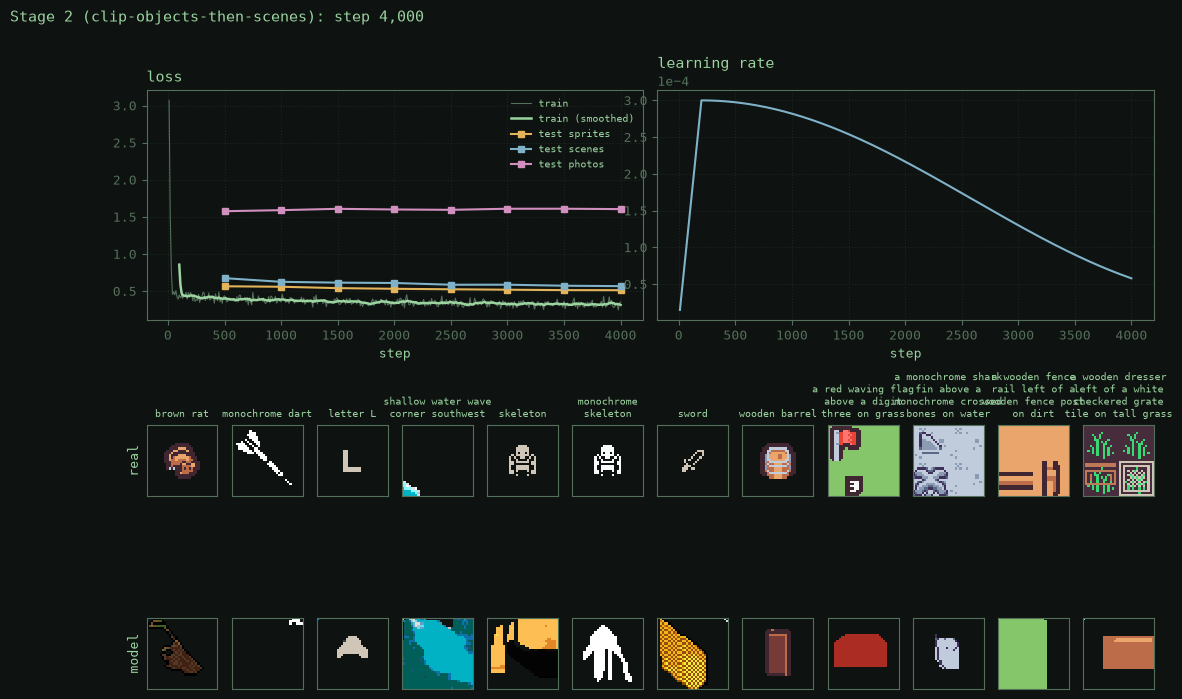

time 0:08:56 │ step 500 │ loss 0.438 │ sprites 0.566 │ scenes 0.675 │ photos 1.577 │ lr 3.0e-04  best
time 0:17:28 │ step 1,000 │ loss 0.355 │ sprites 0.559 │ scenes 0.626 │ photos 1.591 │ lr 2.8e-04  best
time 0:25:57 │ step 1,500 │ loss 0.396 │ sprites 0.541 │ scenes 0.615 │ photos 1.609 │ lr 2.5e-04  best
time 0:34:25 │ step 2,000 │ loss 0.345 │ sprites 0.532 │ scenes 0.610 │ photos 1.600 │ lr 2.2e-04  best
time 0:42:47 │ step 2,500 │ loss 0.341 │ sprites 0.525 │ scenes 0.587 │ photos 1.596 │ lr 1.7e-04  best
time 0:51:15 │ step 3,000 │ loss 0.304 │ sprites 0.520 │ scenes 0.587 │ photos 1.610 │ lr 1.3e-04  best
time 1:00:10 │ step 3,500 │ loss 0.366 │ sprites 0.514 │ scenes 0.573 │ photos 1.611 │ lr 9.0e-05  best
time 1:08:57 │ step 4,000 │ loss 0.355 │ sprites 0.513 │ scenes 0.568 │ photos 1.606 │ lr 5.8e-05  best
stopped step 4,007 │ last checkpoint step 4,000 │ resume run this cell again


In [8]:
train_log: list[dict[str, float]] = []
test_log: list[dict[str, float]] = []
snapshots: list[tuple[int, torch.Tensor]] = []
best = float("inf")
step = 0
if RESUME and CHECKPOINT.exists():
    state = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
    model.load_state_dict(state["model"])
    optimizer.load_state_dict(state["optimizer"])
    step, train_log, test_log = state["step"], state["train_log"], state["test_log"]
    snapshots, best = state["snapshots"], state["best"]
    print(f"resumed from {CHECKPOINT} at step {step:,}")

panel = display(HTML(""), display_id=True)
board = display(HTML(""), display_id=True)
started, recent_steps, window = time.time(), [], []
model.train()
try:
    for batch in DataLoader(train_data, batch_size=BATCH, sampler=order[step * BATCH :].tolist()):
        tick = time.time()
        for group in optimizer.param_groups:
            group["lr"] = learning_rate(step)
        texts, pixels = training_batch(batch, step)
        captions = caption_slot(model, texts, batch["source"], drop=CAPTION_DROP)
        loss = model.loss(captions, pixels)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
        optimizer.step()
        window.append(loss.item())
        step += 1
        recent_steps = (recent_steps + [time.time() - tick])[-50:]

        if step % LOG_EVERY == 0:
            train_log.append({"step": step, "loss": sum(window) / len(window), "lr": learning_rate(step - 1)})
            window = []
            panel.update(HTML(status(recent_steps)))
        phase_end = step in ends[:-1]
        if step % EVAL_EVERY == 0 or step == STEPS or phase_end:
            evaluate()
        if phase_end:
            save_phase(ends.index(step) + 1)
    panel.update(HTML(status(recent_steps)))
    print(retro.log_line({"done": f"{step:,} steps", "best test": f"{best:.3f}", "saved": str(BEST)}))
except KeyboardInterrupt:
    last = test_log[-1]["step"] if test_log else 0
    print(retro.log_line({"stopped": f"step {step:,}", "last checkpoint": f"step {last:,}", "resume": "run this cell again"}))

## Results

How the samples for each preview caption changed, one column per evaluation:

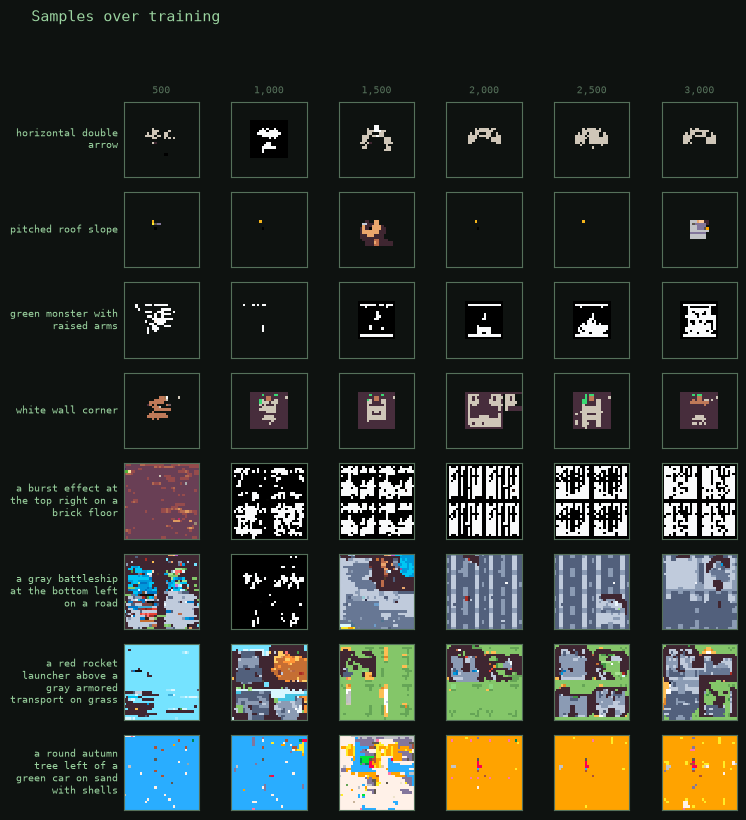

In [21]:
figure = retro.filmstrip([(s, images.numpy()) for s, images in snapshots], PREVIEW)
plt.show()

## Compare runs

Scores every saved run on the test sets: stage 1, stage 2 with learned captions (`checkpoints/finetune-stage1-best.pt`, from an earlier notebook) and every CLIP run saved as `checkpoints/clip-*-best.pt`, each with the caption prefixes it was trained with. Sprite label and position show whether CLIP made the captions matter. Takes a few minutes per run.

- **loss**: test loss per source, with scenes split into unseen sprites and unseen object pairs. Lower is better.
- **sprite label**: for 200 test sprites, how often the true label explains the image better than all of 19 random other labels (chance 0.05).
- **photo query**: the same for 200 test photos and their queries (chance 0.05).
- **position**: for every test scene, how often the true caption beats the same caption with the positions reversed (chance 0.5): the two objects swapped ("a tree left of a barrel" → "a barrel left of a tree"), or left and right exchanged for a single object.

In [22]:
def load_run(path: Path) -> Pixl:
    state = torch.load(path, map_location=DEVICE, weights_only=True)
    # A ClipPixl checkpoint is the only kind with the CLIP input layer.
    kind = ClipPixl if "text_in.weight" in state["model"] else Pixl
    net = kind(Config(**state["config"])).to(DEVICE).eval()
    net.load_state_dict(state["model"])
    net.tags = state.get("tags")
    return net


def reversed_caption(caption: str, objects: str) -> str:
    """The scene caption with the positions reversed: objects swapped, or left and right exchanged."""
    if " at the " in caption:
        return re.sub(r"(at the \w+) (left|right)", lambda m: f"{m[1]} {'right' if m[2] == 'left' else 'left'}", caption)
    for first, second in itertools.permutations(objects.split("|")):
        for relation in ("left of", "above"):
            head = f"{article(first)} {relation} {article(second)}"
            if caption.startswith(head):
                return f"{article(second)} {relation} {article(first)}{caption[len(head):]}"
    raise ValueError(f"unknown caption form: {caption!r}")


def label_accuracy(net: Pixl, data, pool: list[str], n: int, rng: random.Random) -> float:
    """Share of n test images whose true caption has the lowest loss among it and 19 random others."""
    hits = 0
    for index in rng.sample(range(len(data)), n):
        row = data[index]
        candidates = [row["caption"], *rng.sample([c for c in pool if c != row["caption"]], 19)]
        hits += int(pair_losses(net, candidates, row["tokens"].expand(20, -1, -1), [row["source"]] * 20).argmin() == 0)
    return hits / n


# Every test scene; every 25th in a quick run, which still covers both kinds.
scene_index = list(range(0, len(test_sets["scenes"]), 25 if QUICK else 1))
scenes = test_sets["scenes"].select(scene_index)
scene_kinds = np.array([kinds[i] for i in scene_index])
objects = scene_info["objects"]
reversed_captions = [reversed_caption(text, objects[i]) for text, i in zip(scenes["caption"], scene_index)]
pools = {name: sorted(set(train_sets[name]["caption"])) for name in ("sprites", "photos")}


def report(net: Pixl) -> dict[str, float]:
    rng = random.Random(SEED)
    batches, n = (4, 20) if QUICK else (None, 200)
    scene_losses = test_losses(net, scenes, None).numpy()
    wrong = torch.cat([
        pair_losses(net, reversed_captions[start : start + BATCH], scenes[start : start + BATCH]["tokens"], scenes[start : start + BATCH]["source"])
        for start in range(0, len(scenes), BATCH)
    ]).numpy()
    correct = scene_losses < wrong
    return {
        "loss sprites": test_losses(net, test_sets["sprites"], batches).mean().item(),
        "loss scenes (new sprites)": scene_losses[scene_kinds == "new sprites"].mean(),
        "loss scenes (new pair)": scene_losses[scene_kinds == "new pair"].mean(),
        "loss photos": test_losses(net, test_sets["photos"], batches).mean().item(),
        "sprite label": label_accuracy(net, test_sets["sprites"], pools["sprites"], n, rng),
        "photo query": label_accuracy(net, test_sets["photos"], pools["photos"], n, rng),
        "position (new sprites)": correct[scene_kinds == "new sprites"].mean(),
        "position (new pair)": correct[scene_kinds == "new pair"].mean(),
    }


runs = {
    "stage 1": STAGE1,
    "stage 2, learned captions": Path("checkpoints/finetune-stage1-best.pt"),
} | {path.name.removesuffix("-best.pt"): path for path in sorted(Path("checkpoints").glob("clip-*-best.pt")) if "-quick" not in path.name}
if QUICK:
    runs["quick run"] = BEST
results = {}
for name, path in runs.items():
    if path.exists():
        print(f"scoring {name} ({path})")
        results[name] = report(load_run(path))
display(pd.DataFrame(results).T.round(3))

scoring stage 1 (checkpoints/pretrain-best.pt)
scoring stage 2, learned captions (checkpoints/finetune-stage1-best.pt)
scoring clip-finetune (checkpoints/clip-finetune-best.pt)
scoring clip-scratch (checkpoints/clip-scratch-best.pt)


,loss sprites,loss scenes (new sprites),loss scenes (new pair),loss photos,sprite label,photo query,position (new sprites),position (new pair)
stage 1,3.210,1.256,1.301,1.300,0.055,0.255,0.507,0.505
"stage 2, learned captions",0.070,0.192,0.089,1.420,0.345,0.130,0.517,0.519
clip-finetune,0.069,0.188,0.107,1.379,0.415,0.070,0.524,0.639
clip-scratch,0.083,0.237,0.206,1.790,0.365,0.065,0.559,0.722


## Samples

Stage 1, stage 2 with learned captions, this run's objects model (end of phase 1) and its best weights, on the preview captions, at `PREVIEW_TEMPERATURE`. Guidance above 1 pushes each image towards what its caption specifically asks for, at twice the cost per step. Edit `PROMPTS` to try your own captions, e.g. new combinations of sprite labels and positions.

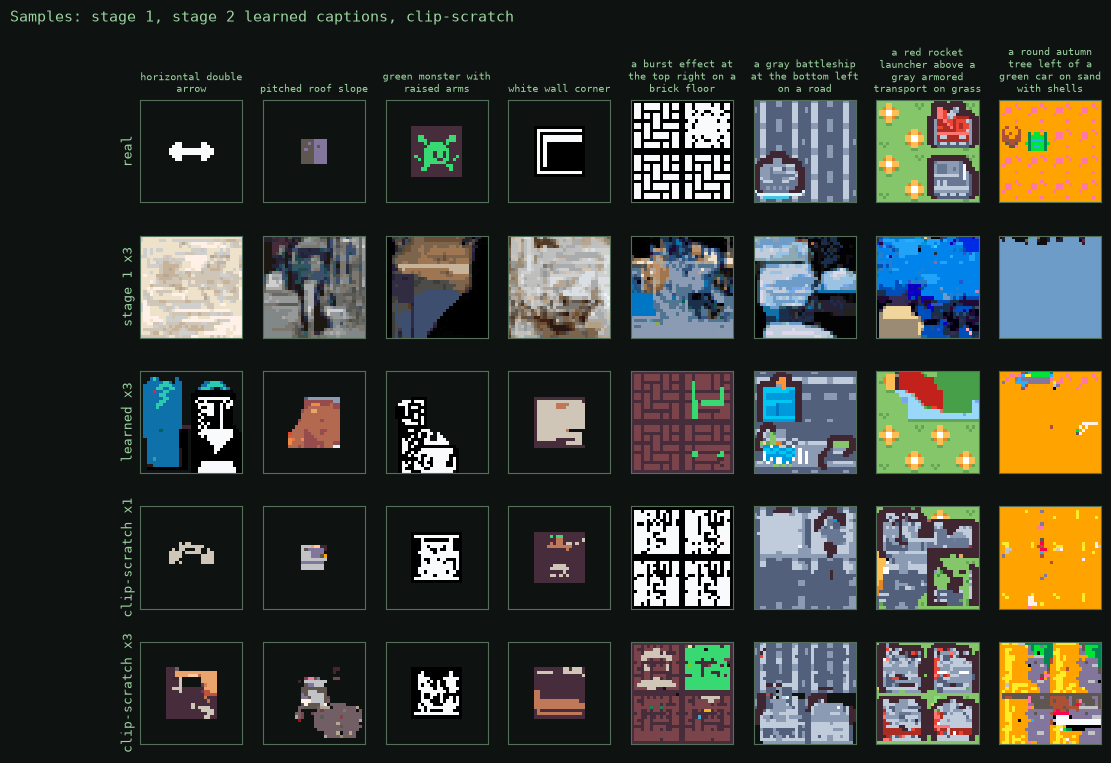

In [23]:
PROMPTS = PREVIEW
PROMPT_SOURCES = PREVIEW_SOURCES  # a source per prompt: picks its prefix in runs trained with TAGS
rows = []
sample_runs = (
    ("stage 1", STAGE1, (3.0,)),
    ("learned", Path("checkpoints/finetune-stage1-best.pt"), (3.0,)),
    (f"{RUN} phase 1", CHECKPOINT.with_name(f"{CHECKPOINT.stem}-phase1.pt"), (3.0,)),
    (RUN, BEST, (1.0, 3.0)),
)
for label, path, scales in sample_runs:
    if not path.exists():
        continue
    net = load_run(path)
    captions = caption_slot(net, PROMPTS, PROMPT_SOURCES)
    for guidance in scales:
        torch.manual_seed(SEED)
        images = net.generate(captions, temperature=PREVIEW_TEMPERATURE, top_k=32, guidance=guidance).view(-1, 32, 32).cpu().numpy()
        rows.append((f"{label} x{guidance:g}", images))
figure = retro.grid([("real", references), *rows], PROMPTS, f"Samples: stage 1, stage 2 learned captions, {RUN}")
plt.show()